```{contents}
:local:
:depth: 2
```

# 4.4 Physics-Informed Machine Learning

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 12, Lesson 3: *Physics-Informed Neural Networks*
- Module 12, Lesson 4: *PINNs for a Chemical Reactor*
- Module 12, Lesson 5: *Lagrangian Duality in Physics-Informed ML*
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Write the loss function of a physics-informed neural network (PINN) and explain what collocation points are and why they need no data.
- Train a PINN in PyTorch, using automatic differentiation for the derivatives in the governing equations.
- Show, on a reactor, that a PINN extrapolates where a plain network trained on the same data does not.
- Pose physics-informed training as a constrained optimization problem and train it by dual ascent on a Lagrange multiplier, connecting the penalty weight to the multipliers of Topic 2.3.
:::

In {doc}`Topic4.3-Hybrid_Modeling` the physics was placed *around* a network: the balances were solved exactly, and the network supplied one unknown term. A **physics-informed neural network** (PINN) reverses this arrangement, since the network is the whole model, mapping inputs straight to the solution, and the physics enters only through the loss function that is used for training. The lectures present this as another form of hybrid modeling, one where the governing equations act as an extra source of training data that is free and available everywhere.

## What a physics-informed network is

Suppose that the quantity of interest, $u(x)$, obeys a known differential equation $\mathcal{N}[u](x) = 0$ (for example a mole balance or a conservation law), and that a few measurements $u_i$ are available at points $x_i$. A plain network $u_\theta(x)$ with weights $\theta$ would be trained by minimizing the data misfit; a PINN adds the residual of the equation, which is evaluated at a second set of points $x_j^c$:

$$
\mathcal{L}(\theta) = \underbrace{\frac{1}{N_d}\sum_{i=1}^{N_d} \big(u_\theta(x_i) - u_i\big)^2}_{\text{data}} \;+\; \mu \underbrace{\frac{1}{N_c}\sum_{j=1}^{N_c} \mathcal{N}[u_\theta](x_j^c)^2}_{\text{physics}}.
$$

There are three features of this loss that are important:

1. **The derivatives come from automatic differentiation.** The network is a smooth function of its input, so $du_\theta/dx$ and $d^2u_\theta/dx^2$ are computed exactly by the same machinery that computes gradients for training.
2. **The collocation points $x_j^c$ need no data.** The residual only asks whether the network satisfies the equation there, so we may place collocation points anywhere, including far outside the measured region. This is why a PINN can extrapolate, since it is trained on the physics even where it has no data.
3. **The weight $\mu$ sets the balance.** With $\mu = 0$ we have a plain network. As $\mu$ grows, the network is pushed harder toward solutions of the equation. Choosing $\mu$ is a hyperparameter problem, and the last section of this topic replaces that choice with a Lagrange multiplier.

The physics term is a **soft constraint**: it is penalized rather than enforced, so the trained network only satisfies the equation approximately. This is the main contrast with the serial hybrid of Topic 4.3, where the balances held exactly by construction. A PINN is easier to set up (any network, any equation, and no ODE solver in the loop) but does not offer any guarantee. PINNs can be used *forward*, as a fast surrogate for an expensive simulation, or *inverse*, where unknown parameters in the equation are estimated from data by making those parameters trainable alongside $\theta$; both uses were made popular by Raissi, Perdikaris and Karniadakis (2019).

In the lectures PINNs are built with SciANN, a Keras wrapper where the inputs are declared as `Variable`s, the network as a `Functional` of them, derivatives with `sn.math.diff`, each loss term as a `Data` target (data, or zero for an equation residual), and the whole model as a `SciModel` that is trained with Keras options. In PyTorch each of these pieces can be written in a line or two of ordinary code. The lectures also write the loss as a convex combination, $(1-\mu)\,\text{data} + \mu\,\text{physics}$ with $0 \le \mu < 1$ (the reactor runs use $\mu = 0.5$ and $0.99$); dividing by $1-\mu$ shows that this is the same as our form with weight $\mu/(1-\mu)$.

:::{exercise}
:label: ex-t44-residual

Write the PINN residual $\mathcal{N}[u_\theta]$ for the steady heat equation in a rod with a heat source, $k\,u'' + q = 0$, and list the extra loss terms you would need for boundary conditions $u(0) = u_0$ and $u(L) = u_L$. Which terms need measured data and which do not?
:::

## A first PINN

:::{admonition} Adapted from the course notebook
:class: note
Adapted from `NeuralNets-HybridModels-PINNs.ipynb` (MIT License, © 2022 Data-Driven PSE Lab @ChBE-GT), section "PINNs Using SciANN – PDE Example". The notebook fits $f = \sin x \sin y$ with the PDE $f_{xx} + f_{yy} + 2f = 0$ in SciANN; we use its one-dimensional analog in PyTorch so that it trains in seconds.
:::

The example in the lecture fits an "unknown" function from data on a small domain and asks the network to predict on a domain that is twice as wide. The one-dimensional analog of this problem is $u = \sin x$, which satisfies $u'' + u = 0$. The network is given 30 samples on $[-\pi, \pi]$ and asked for predictions on $[-3\pi, 3\pi]$, while the PINN is given the same 30 samples plus the residual $u'' + u$ at 200 collocation points that are spread over the whole wider domain.

plain network: RMS error inside the data 0.0014, outside 1.3087 (2.1 s)


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


PINN         : RMS error inside the data 0.0009, outside 0.0086 (1.7 s)


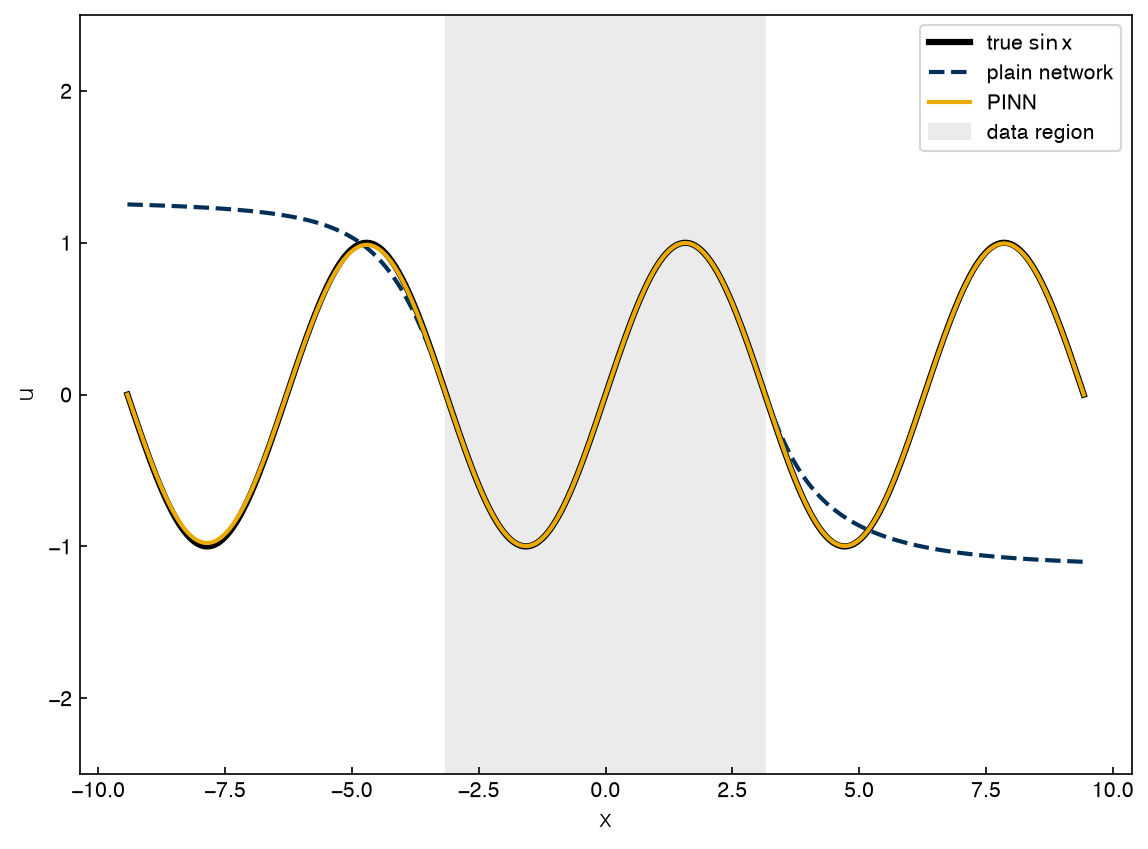

In [1]:
%matplotlib inline
import sys, time
sys.path.insert(0, '..')
import numpy as np
import torch
import matplotlib.pyplot as plt
plt.style.use('../settings/plot_style.mplstyle')
from _lib.part4b_tools import Reactor as R, mlp, train

L = 3 * np.pi                                              # inputs are scaled by L into [-1, 1]
x_d = np.linspace(-np.pi, np.pi, 30)
xd, ud = torch.tensor(x_d[:, None] / L), torch.tensor(np.sin(x_d)[:, None])
xc = torch.tensor(np.linspace(-L, L, 200)[:, None] / L, requires_grad=True)

def residual(net):
    """u'' + u at the collocation points, by automatic differentiation (chain rule for the scaling)."""
    u = net(xc)[:, 0]
    du = torch.autograd.grad(u.sum(), xc, create_graph=True)[0][:, 0]
    d2u = torch.autograd.grad(du.sum(), xc, create_graph=True)[0][:, 0]
    return d2u / L ** 2 + u

x_t = np.linspace(-L, L, 301)
inside = np.abs(x_t) <= np.pi
fig, ax = plt.subplots()
ax.plot(x_t, np.sin(x_t), 'k-', lw=3, label='true $\\sin x$')
for mu, name in ((0.0, 'plain network'), (1.0, 'PINN')):
    net = mlp(1, 1, width=20, depth=3, seed=0)
    loss = lambda: ((net(xd) - ud) ** 2).mean() + mu * (residual(net) ** 2).mean()
    t0 = time.time()
    train(net.parameters(), loss, steps=3000, lr=5e-3)
    with torch.no_grad():
        err = net(torch.tensor(x_t[:, None] / L))[:, 0].numpy() - np.sin(x_t)
    print(f"{name:13s}: RMS error inside the data {np.sqrt(np.mean(err[inside] ** 2)):.4f}, "
          f"outside {np.sqrt(np.mean(err[~inside] ** 2)):.4f} ({time.time() - t0:.1f} s)")
    ax.plot(x_t, err + np.sin(x_t), '--' if mu == 0 else '-', label=name)
ax.axvspan(-np.pi, np.pi, color='0.92', label='data region')
ax.set_ylim(-2.5, 2.5)
ax.set_xlabel('$x$')
ax.set_ylabel('$u$')
ax.legend(fontsize=10);

Inside the data region both networks are accurate, to about 0.001. Outside the data region, however, the error of the plain network is of order one, since there is nothing in the data that would force the network to keep oscillating. The error of the PINN outside the data stays below 0.01, because the equation (which is enforced at collocation points where there are no data) carries the oscillation out into the region without data. The data are used to pick which solution of $u'' + u = 0$ is wanted (since any $a \sin x + b \cos x$ is a solution), and the physics is used to extend that solution.

:::{exercise}
:label: ex-t44-collocation

Rerun the PINN with the collocation points restricted to the data region $[-\pi, \pi]$, as in the original notebook, where the residual was evaluated only at the data inputs. How much of the PINN's advantage outside the data survives? What does this tell you about where collocation points should go?
:::

## A PINN for the reactor

The reactor example in the lectures is a non-isothermal plug-flow reactor with three reactions, six species and an energy balance, where a network maps reactor volume to all of the flows and the temperature and the PFR balances form the physics loss. Here the series reactor of Topic 4.3 at 350 K is used instead, but now with the assumption that the full kinetics are known (including the inhibition), so that the question is purely one of data versus physics. The data are five noisy measurements of $C_A$ and $C_B$ at residence times of up to 2 min, and the goal is to predict the profile out to 8 min.

The network maps $\tau$ to $(C_A, C_B)$, and the physics loss has three parts, which are the two mole-balance residuals at 81 collocation points spread over $[0, 8]$ min and the inlet condition $C_A(0) = 1$, $C_B(0) = 0$:

$$
\mathcal{N}_A = \frac{dC_A}{d\tau} + r_1, \qquad \mathcal{N}_B = \frac{dC_B}{d\tau} - r_1 + k_2 C_B, \qquad r_1 = \frac{k_1 C_A}{1 + K C_A}.
$$

In [2]:
T = 350.
k1, k2, K = R.k1(T), R.k2(T), R.K_ADS
rng = np.random.default_rng(0)
tau_d = np.array([0.25, 0.5, 1.0, 1.5, 2.0])                       # min, sparse data
ca, cb = R.simulate(T, tau_d, n=200)
Y = np.c_[ca, cb] + rng.normal(0, 0.01, (len(tau_d), 2))           # mol/L, noise 0.01
TS = 4.0                                                           # tau is scaled by 4 min
td, Yd = torch.tensor(tau_d[:, None] / TS), torch.tensor(Y)
tc = torch.tensor(np.linspace(0, 8, 81)[:, None] / TS, requires_grad=True)
zero = torch.zeros(1, 1, dtype=torch.double)
feed = torch.tensor([R.CA0, 0.0], dtype=torch.double)

def physics(net):
    """Mean squared mole-balance residual at the collocation points plus the inlet condition."""
    c = net(tc)
    dA = torch.autograd.grad(c[:, 0].sum(), tc, create_graph=True)[0][:, 0] / TS
    dB = torch.autograd.grad(c[:, 1].sum(), tc, create_graph=True)[0][:, 0] / TS
    r1 = k1 * c[:, 0] / (1 + K * c[:, 0])
    res = torch.stack([dA + r1, dB - r1 + k2 * c[:, 1]], 1)
    return (res ** 2).mean() + ((net(zero)[0] - feed) ** 2).sum()

def data_loss(net):
    return ((net(td) - Yd) ** 2).mean()

tau_t = np.linspace(0, 8, 161)
truth = np.column_stack(R.simulate(T, tau_t, n=400))          # columns C_A, C_B

def errors(net):
    with torch.no_grad():
        p = net(torch.tensor(tau_t[:, None] / TS)).numpy()
    e = (p - truth) ** 2
    return np.sqrt(e[tau_t <= 2].mean()), np.sqrt(e[tau_t > 2].mean()), p

The function `physics` is the whole of the "physics-informed" part. The two calls to `torch.autograd.grad` give $dC_A/d\tau$ and $dC_B/d\tau$ at every collocation point, and `create_graph=True` keeps these derivatives differentiable so that the optimizer can take gradients of the residual with respect to the weights. Next, a plain network ($\mu = 0$) and a PINN ($\mu = 1$) are trained from the same initial weights.

plain network   : data MSE 2.9e-05, physics loss 5.7e-03, RMS error tau <= 2 min 0.0046, tau > 2 min 0.1354 mol/L (1.3 s)


PINN (mu = 1)   : data MSE 4.8e-05, physics loss 4.3e-06, RMS error tau <= 2 min 0.0011, tau > 2 min 0.0033 mol/L (1.3 s)


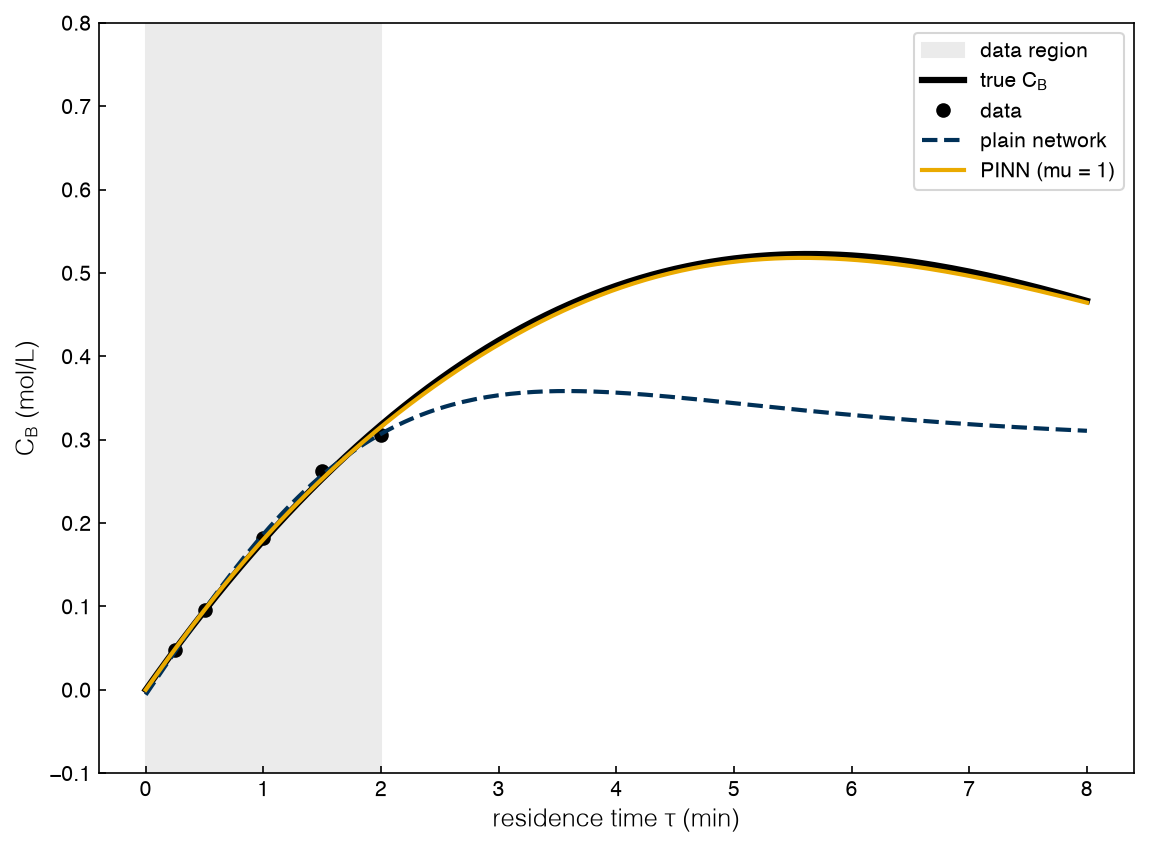

In [3]:
fig, ax = plt.subplots()
ax.axvspan(0, 2, color='0.92', label='data region')
ax.plot(tau_t, truth[:, 1], 'k-', lw=3, label='true $C_B$')
ax.plot(tau_d, Y[:, 1], 'ko', label='data')
nets = {}
for mu, name in ((0.0, 'plain network'), (1.0, 'PINN (mu = 1)')):
    net = mlp(1, 2, width=20, depth=3, seed=0)
    t0 = time.time()
    train(net.parameters(), lambda: data_loss(net) + mu * physics(net), steps=3000, lr=5e-3)
    e_in, e_out, p = errors(net)
    nets[mu] = net
    print(f"{name:16s}: data MSE {data_loss(net).item():.1e}, physics loss {physics(net).item():.1e}, "
          f"RMS error tau <= 2 min {e_in:.4f}, tau > 2 min {e_out:.4f} mol/L ({time.time() - t0:.1f} s)")
    ax.plot(tau_t, p[:, 1], '--' if mu == 0 else '-', label=name)
ax.set_ylim(-0.1, 0.8)
ax.set_xlabel(r'residence time $\tau$ (min)')
ax.set_ylabel(r'$C_B$ (mol/L)')
ax.legend(fontsize=10);

The two networks fit the five data points about equally well, although the data misfit of the PINN is slightly larger because it is no longer free to chase the noise. Beyond the data the plain network fails, with an RMS error of 0.135 mol/L, while the error of the PINN is 0.003 mol/L; the PINN has learned the solution of the mole balances, which is more than a curve through five points. The lectures report the same pattern for the non-isothermal PFR: similar training error, an extrapolation error several times smaller for the PINN, and a regularizing effect when data are scarce. This regularization can be seen here as well, inside the data region, where the RMS error of the plain network for $\tau \le 2$ min is 0.0046 mol/L (about the noise level) because it follows the noisy points, while the error of the PINN is 0.0011 mol/L because the physics does not allow it to follow them.

Once it is trained, the PINN is a closed-form surrogate for the reactor at this temperature. Evaluating it costs one forward pass with no ODE solver, which is why the lectures suggest PINNs as replacements for expensive ODE or PDE models inside optimization. If $T$ were added as a second input and the collocation points were spread over a range of temperatures, the same network could be embedded in Pyomo with OMLT exactly as in Topic 4.3.

The simplest design question that can already be answered is the residence time that maximizes $C_B$ at 350 K. Since the true optimum lies outside the data, this is a test of extrapolation.

In [4]:
tau_opt_true = tau_t[np.argmax(truth[:, 1])]
for mu, name in ((0.0, 'plain network'), (1.0, 'PINN (mu = 1)')):
    p = errors(nets[mu])[2]
    k = np.argmax(p[:, 1])
    ca_k, cb_k = R.simulate(T, [tau_t[k]], n=400)
    print(f"{name:14s}: best tau {tau_t[k]:.2f} min, predicted C_B {p[k, 1]:.3f}, true C_B there {cb_k[0]:.3f}")
print(f"true optimum : tau {tau_opt_true:.2f} min, C_B {truth[:, 1].max():.3f}")

plain network : best tau 3.60 min, predicted C_B 0.358, true C_B there 0.463
PINN (mu = 1) : best tau 5.60 min, predicted C_B 0.518, true C_B there 0.523
true optimum : tau 5.65 min, C_B 0.523


The PINN puts the optimum at 5.60 min, compared with the true 5.65 min, and predicts 0.518 mol/L of B against the 0.523 mol/L given by the reactor. The plain network puts the optimum at 3.60 min, which is the point where the predicted curve turns over, and the reactor would only give 0.463 mol/L there, 11% below the best. In other words, the optimum of the plain network is simply wherever the curve happens to turn over beyond the data, whereas the optimum of the PINN is correct because the physics was enforced in the region where the optimum lies.

:::{exercise}
:label: ex-t44-inverse

Turn this into an inverse problem. Make the inhibition constant trainable, `K = torch.nn.Parameter(torch.tensor(0.5, dtype=torch.double))`, include it in the optimizer's parameters, and train the PINN on data out to 4 min. How close does the learned $K$ come to the true 2 L/mol? Repeat with the noise raised to 0.03 mol/L.
:::

## Physics as a constraint: Lagrangian duality

The weight $\mu$ in the PINN loss is unsatisfying, since it has no physical meaning, the right value depends on the scaling of the data and the equations, and it is usually tuned by trial and error. The last lecture of Module 12 presents a more principled view, following the work of Fioretto and co-workers (2020), which comes straight from {doc}`../2-nonlinear_mixed_integer/Topic2.3-Duality`.

Instead of trading data against physics with a fixed weight, the training problem can be written as what it really is, which is a constrained optimization: the data should be fit as well as possible *subject to* the physics being satisfied to a tolerance $\epsilon$,

$$
\min_{\theta}\; J(\theta) = \frac{1}{N_d}\sum_i \big(u_\theta(x_i) - u_i\big)^2 \quad \text{s.t.} \quad g(\theta) = \text{physics loss} \le \epsilon.
$$

The Lagrangian of this problem is $\mathcal{L}(\theta, \lambda) = J(\theta) + \lambda\,(g(\theta) - \epsilon)$ with $\lambda \ge 0$. If we compare this with the PINN loss, the penalty weight $\mu$ *is* a Lagrange multiplier, but one that was fixed in advance instead of being solved for, and Topic 2.3 gives us the tools that are needed to solve for it.

Engineering supplies many constraints like this besides a differential equation: mass and energy are conserved, concentrations and flows cannot be negative, and a fraction lies between 0 and 1. Fioretto and co-workers give each constraint $j$ its own multiplier $\lambda_j$ and measure the violation by a **violation degree** $\nu_j(\theta) \ge 0$ (for an inequality $g_j \le 0$, $\nu_j = \max(0, g_j)$; for an equality, $|h_j|$), so that the Lagrangian is $J(\theta) + \sum_j \lambda_j \nu_j(\theta)$ and the dual problem is $\max_{\lambda \ge 0} \min_\theta$ of it. Here only the simplest case is used, with one constraint on the total physics loss.

- **Weak duality.** For any $\lambda \ge 0$, the dual function $d(\lambda) = \min_\theta \mathcal{L}(\theta, \lambda)$ is a lower bound on the best constrained data fit. Training a PINN with a fixed $\mu$ is evaluating $d(\mu)$, at least approximately.
- **Dual ascent.** The best bound comes from maximizing $d(\lambda)$, and the slope of $d$ at $\lambda$ is the constraint value $g(\theta^*(\lambda)) - \epsilon$. So we alternate: take a training step in $\theta$ on $\mathcal{L}$, then nudge $\lambda$ up if the physics is violated and down if it is over-satisfied, $\lambda \leftarrow \max\big(0,\ \lambda + s\,(g(\theta) - \epsilon)\big)$.
- **Complementary slackness and prices.** At the solution, either the physics constraint is active ($g = \epsilon$) and $\lambda > 0$, or it is slack and $\lambda = 0$. As in Topic 2.3, $\lambda$ is a price: the amount of data misfit we would accept per unit tightening of the physics tolerance.

There is one honest caveat. Since network training is nonconvex, strong duality is not guaranteed and the inner minimization is only approximate; the lectures make the same point, noting that if the global optimum were found the constraints would be satisfied, but that in practice this cannot be guaranteed. Even so, the approach turns an unphysical weight into a physical tolerance and finds the weight automatically.

The tolerance is set at $\epsilon = 10^{-5}$, which corresponds to a residual of roughly 0.003 mol/(L min) RMS, and three fixed weights are compared with dual ascent. The multiplier $\lambda$ is updated after every Adam step, and each update is clipped to $s$ times one tolerance, which keeps the large violations early in training from throwing $\lambda$ far past the final value.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


                 final weight  data MSE  physics g g <= eps?  RMS err tau>2
fixed mu = 0.03          0.03   3.4e-05    2.6e-04     False         0.0391
fixed mu = 0.3           0.30   4.6e-05    1.7e-05     False         0.0105
fixed mu = 3.0           3.00   5.1e-05    2.2e-06      True         0.0014
dual ascent              0.30   4.4e-05    1.0e-05      True         0.0078


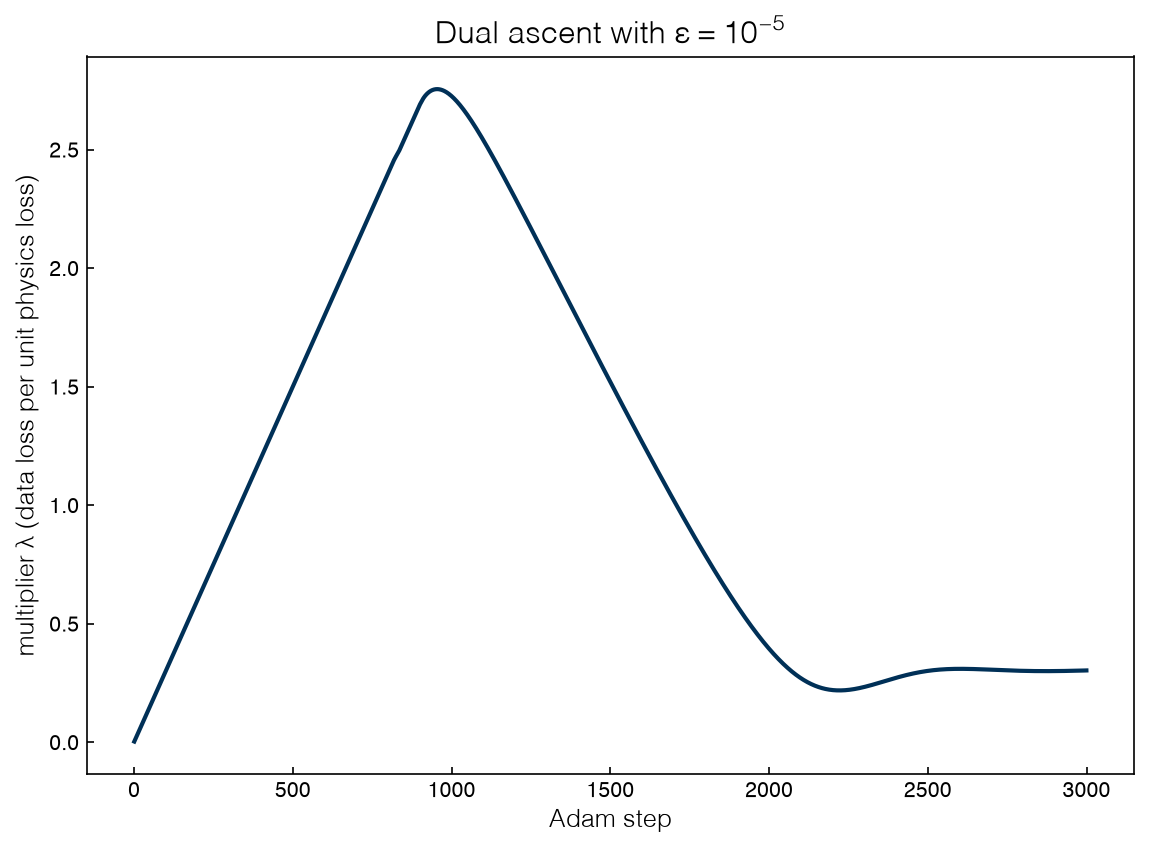

In [5]:
EPS = 1e-5

def fit(mu=None, s=None, steps=3000):
    """Fixed weight mu, or dual ascent on lambda with step s. Returns the net and the lambda history."""
    net = mlp(1, 2, width=20, depth=3, seed=0)
    opt = torch.optim.Adam(net.parameters(), lr=5e-3)
    lam, lam_hist = (mu if s is None else 0.0), []
    for _ in range(steps):
        opt.zero_grad()
        g = physics(net)
        (data_loss(net) + lam * (g - EPS)).backward()
        opt.step()
        if s is not None:                                       # dual ascent, clipped step
            lam = max(0.0, lam + s * float(np.clip(g.item() / EPS - 1, -1, 1)))
        lam_hist.append(lam)
    return net, np.array(lam_hist)

runs = {f'fixed mu = {mu}': fit(mu=mu) for mu in (0.03, 0.3, 3.0)}
runs['dual ascent'] = fit(s=3e-3)
print(f"{'':16s}{'final weight':>13s}{'data MSE':>10s}{'physics g':>11s}{'g <= eps?':>10s}{'RMS err tau>2':>15s}")
for name, (net, lam_hist) in runs.items():
    g = physics(net).item()
    print(f"{name:16s}{lam_hist[-1]:13.2f}{data_loss(net).item():10.1e}{g:11.1e}{str(g <= EPS * 1.05):>10s}"
          f"{errors(net)[1]:15.4f}")

fig, ax = plt.subplots()
ax.plot(runs['dual ascent'][1])
ax.set_xlabel('Adam step')
ax.set_ylabel(r'multiplier $\lambda$ (data loss per unit physics loss)')
ax.set_title(rf'Dual ascent with $\epsilon = 10^{{-5}}$');

The fixed weights show the tuning problem. At $\mu = 0.03$ the physics loss is 26 times the tolerance and the extrapolation is poor; at $\mu = 0.3$ it is close but still violated; and at $\mu = 3$ the physics is satisfied with room to spare. Without the tolerance, it is not clear which of these is "right".

Dual ascent is able to answer this question. In the plot the multiplier climbs while the physics is violated, overshoots while the network catches up, and then settles at about 0.3, where the physics loss sits at the tolerance (to within a few percent); this means that the constraint is active and the multiplier is positive, as is required by complementary slackness. The settled multiplier also agrees with the sweep, which bracketed the weight that just satisfies the tolerance between 0.3 and 3. A tighter $\epsilon$ would give a larger multiplier and, as can be seen in the $\mu = 3$ row, better extrapolation, at the price of a slightly worse data fit.

The lectures close with applications where this matters more than in our small example, such as learning fast approximations of AC optimal power flow, where the physics are Kirchhoff's laws and the power-flow equations, and of gas-compressor networks, where the physics are the flow and balance equations. In both of these applications a network that violates the physics produces dispatches that cannot be implemented, so the constraints need to be enforced as tightly as possible.

:::{exercise}
:label: ex-t44-dual

Rerun the dual-ascent fit with $\epsilon = 10^{-6}$ and $\epsilon = 10^{-4}$. Plot the final data MSE against the final physics loss for the three tolerances and for the fixed-weight runs on one log-log plot. Estimate the slope of that trade-off curve near $\epsilon = 10^{-5}$ and compare it with the settled multiplier. Which result from Topic 2.3 predicts the relation you see?
:::

## Summary

- A PINN is a network trained on a loss that adds the residual of the governing equations, evaluated by automatic differentiation at collocation points, to the data misfit.
- Collocation points need no data, so the physics can be enforced where there are no measurements. That is why PINNs extrapolate: on the sine example the error outside the data fell from order one to below 0.01, and on the reactor from 0.135 to 0.003 mol/L.
- The physics in a PINN is a soft constraint, satisfied approximately. The serial hybrid of Topic 4.3 enforced it exactly but needed an ODE solver in the training loop.
- The penalty weight is a Lagrange multiplier fixed in advance. Writing the physics as a constraint with a tolerance and training by dual ascent finds the multiplier instead; on the reactor it settled near 0.3, with the physics constraint active.
- The bonus topics on uncertainty turn from uncertain models to uncertain parameters: how to optimize when the data in the model are themselves uncertain.

## Additional Reading

- M. Raissi, P. Perdikaris and G. E. Karniadakis, "Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations," *Journal of Computational Physics* 378 (2019) 686–707.
- F. Fioretto, P. Van Hentenryck, T. W. K. Mak, C. Tran, F. Baldo and M. Lombardi, "Lagrangian duality for constrained deep learning," in *Machine Learning and Knowledge Discovery in Databases (ECML PKDD 2020)*, Springer (2021). The approach of the last lecture.
- G. E. Karniadakis, I. G. Kevrekidis, L. Lu, P. Perdikaris, S. Wang and L. Yang, "Physics-informed machine learning," *Nature Reviews Physics* 3 (2021) 422–440. A broad review.
- E. Haghighat and R. Juanes, "SciANN: A Keras/TensorFlow wrapper for scientific computations and physics-informed deep learning using artificial neural networks," *Computer Methods in Applied Mechanics and Engineering* 373 (2021) 113552. The package used in the lectures.
- J. Nocedal and S. J. Wright, *Numerical Optimization*, 2nd ed., Springer (2006). Chapter 17 covers penalty and augmented Lagrangian methods, the classical relatives of dual ascent.